# 4-2 seaborn 统计图表

目标：从本地历史教学数据画直方图、箱线图、散点图，理解分箱、分布和关联。不下载在线数据，不机械删离群，不把相关当因果。

> **这是参考答案版**，保留完整示例与解法。代码格下方的输出会在运行后出现。
> 建议先在 `notebooks/` 文件夹里的学生版自己做一遍，卡住了再来这里对照。

In [1]:
import sys
sys.path.insert(0, "..")
from dacheck import check, hint, setup_chinese_font
import pandas as pd

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")
setup_chinese_font(verbose=True)
tips = pd.read_csv("../data/public/tips.csv")
penguins = pd.read_csv("../data/public/penguins.csv")
print("tips 与 penguins 行列：", tips.shape, penguins.shape)
print(penguins.isna().sum())

tips 与 penguins 行列： (244, 7) (344, 7)
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


tips 是历史餐厅样本，账单和小费单位美元；penguins 是历史企鹅测量，喙长毫米、体重克。不要调用 `sns.load_dataset`，随包 CSV 已够用。

## 示范：直方图看数值落在哪些区间

`bins=12` 是十二个区间，不是十二笔消费。改变分箱影响细节，纵轴默认计数，不是概率。

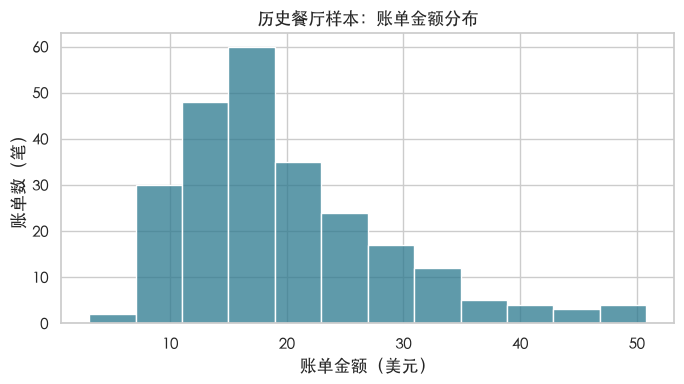

In [3]:
fig_hist, ax_hist = plt.subplots(figsize=(7, 4))
sns.histplot(data=tips, x="total_bill", bins=12, ax=ax_hist, color="#2a788e")
ax_hist.set(title="历史餐厅样本：账单金额分布",
            xlabel="账单金额（美元）", ylabel="账单数（笔）")
fig_hist.tight_layout()
plt.show()

## 示范：箱线图看中位数和离散程度

箱中横线为中位数，箱体覆盖中间 50% 的值。默认须外的点是离群候选，不是必然错误；高账单可能来自多人聚餐。另看样本量，不能凭图形判断因果或统计显著。

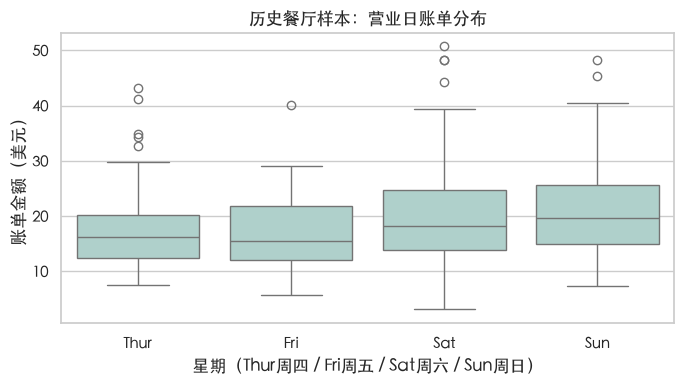

      count  median
day                
Fri      19   15.38
Sat      87   18.24
Sun      76   19.63
Thur     62   16.20


In [4]:
fig_box, ax_box = plt.subplots(figsize=(7, 4))
sns.boxplot(data=tips, x="day", y="total_bill",
            order=["Thur", "Fri", "Sat", "Sun"], ax=ax_box, color="#a9d6cf")
ax_box.set(title="历史餐厅样本：营业日账单分布",
           xlabel="星期（Thur周四 / Fri周五 / Sat周六 / Sun周日）",
           ylabel="账单金额（美元）")
fig_box.tight_layout()
plt.show()
print(tips.groupby("day")["total_bill"].agg(["count", "median"]))

## 示范：散点必须是一行的一对值

本图只要求喙长、体重和物种齐全。缺失性别不影响本图；按所需字段建立入图副本，不删除原表所有缺失。

原表、入图、未入图： 344 342 2


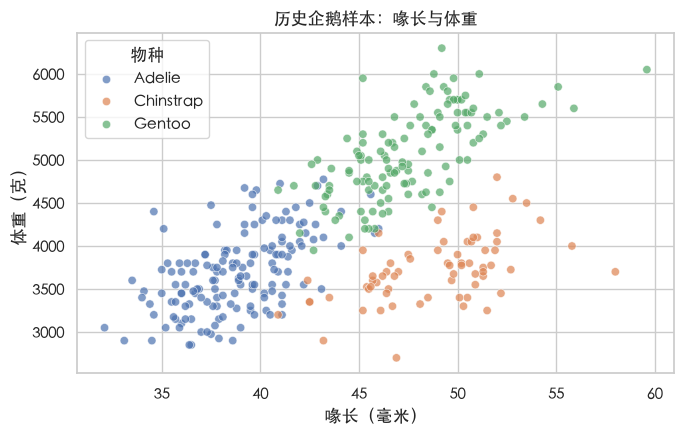

In [5]:
required = ["bill_length_mm", "body_mass_g", "species"]
plot_data = penguins.dropna(subset=required).copy()
excluded = penguins.loc[penguins[required].isna().any(axis=1)].copy()
print("原表、入图、未入图：", len(penguins), len(plot_data), len(excluded))
fig_scatter, ax_scatter = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=plot_data, x="bill_length_mm", y="body_mass_g",
                hue="species", alpha=0.7, ax=ax_scatter)
ax_scatter.set(title="历史企鹅样本：喙长与体重",
               xlabel="喙长（毫米）", ylabel="体重（克）")
ax_scatter.legend(title="物种")
fig_scatter.tight_layout()
plt.show()

按物种分色，可以看到组别影响。不要分别排序两个测量列后配对；那会伪造关系。透明度改善重叠展示，不改变测量权重。

## 练习 1：有效入图数量

独立计算所需三列完整的行数，不因其他字段缺失而排除。

In [6]:
plot_rows_answer = penguins.dropna(subset=["bill_length_mm", "body_mass_g", "species"]).shape[0]
check("4-2.1", plot_rows_answer)

True

## 练习 2：账单中位数

按 Thur、Fri、Sat、Sun 的顺序交付中位数 Series，不是均值。

In [7]:
median_answer = tips.groupby("day")["total_bill"].median().reindex(["Thur", "Fri", "Sat", "Sun"])
check("4-2.2", median_answer)

True

## 练习 3：不分色的散点图

用 `plot_data` 画一张不设 hue 的散点图。标题“企鹅测量关系”，横轴“喙长（毫米）”，纵轴“体重（克）”，提交 Axes。

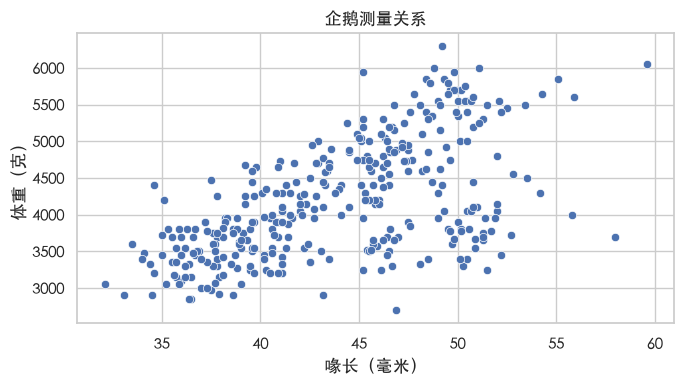

True

In [8]:
exercise_fig, scatter_ax_answer = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=plot_data, x="bill_length_mm", y="body_mass_g", ax=scatter_ax_answer)
scatter_ax_answer.set(title="企鹅测量关系", xlabel="喙长（毫米）", ylabel="体重（克）")
exercise_fig.tight_layout()
plt.show()
check("4-2.3", scatter_ax_answer)

## 练习 4：结论边界

喙长和体重的关联不能证明“喙长导致体重上升”。提交提醒短语“相关不等于因果”。

In [9]:
causal_answer = "相关不等于因果"
check("4-2.4", causal_answer)

True

## 小测与验收

箱线图须外的点要删吗？

<details><summary>参考答案</summary>不能机械删除。先检查源记录、测量单位和业务含义，必要时标记、复核并比较有无这些点的结果。</details>

验收：断网读取本地文件；计数、美元、毫米、克标签正确；解释分箱和中位数；成对测量不乱配；记录入图范围；不做因果推断。求职作品注明历史样本限制，图形用于探索，不冒充已验证的真实运营决策。